In [1]:
!pip install -q pandas



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\surfa\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
!pip install -q seaborn


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\surfa\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [3]:
!pip install -q matplotlib


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\surfa\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [4]:
!pip install -q tensorflow


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\surfa\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


### **About Dataset**
- MNIST is a subset of a larger set available from NIST (it's copied from http://yann.lecun.com/exdb/mnist/)
- The MNIST database of handwritten digits has a training set of 60,000 examples, and a test set of 10,000 examples.

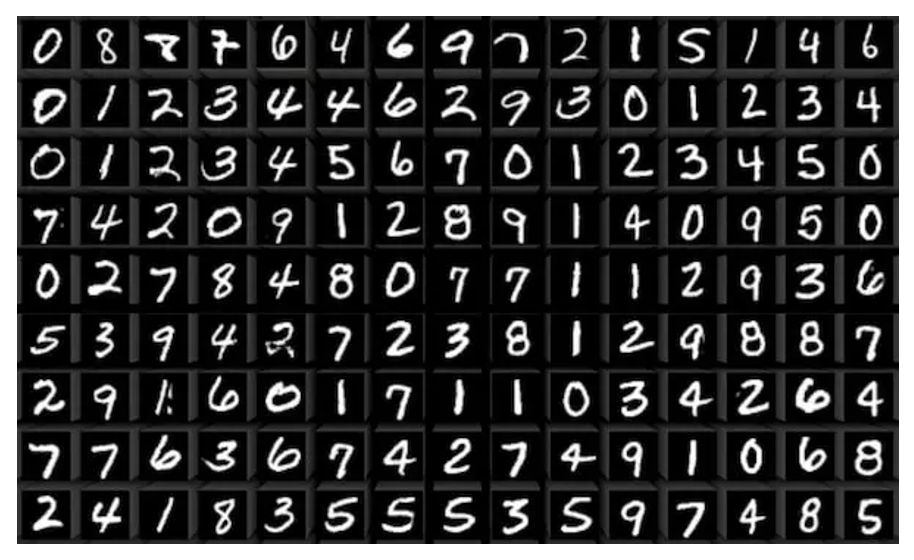

In [5]:
import tensorflow as tf
from tensorflow import keras

In [6]:
(X_train,y_train),(X_test, y_test) = keras.datasets.mnist.load_data()

In [7]:
print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [8]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

<Figure size 640x480 with 0 Axes>

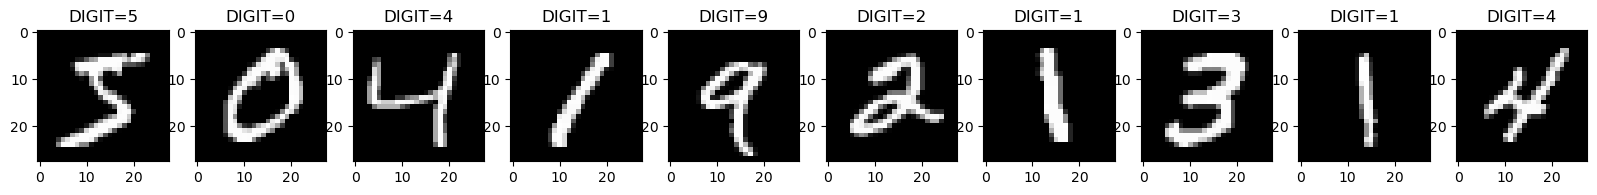

In [9]:
import matplotlib.pyplot as plt
plt.gray()
figure, axis = plt.subplots(ncols=10, figsize=(20,20))
for index in range(10):
   axis[index].imshow(X_train[index])
   axis[index].set_title(f"DIGIT={y_train[index]}")
plt.show()   


In [10]:
#si il y a un GPU disponible, on active la croissance de la mémoire pour éviter les erreurs de mémoire
gpus = tf.config.experimental.list_logical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu,True)

In [11]:
print(gpus)

[]


## ANN

In [26]:
#X_train_flattened = X_train.reshape(len(X_train), 28*28)
#X_test_flattened = X_test.reshape(len(X_test), 28*28)

In [12]:
#Avec ANN la premiere couche est un vecteur
#C'est quoi la couche dense

ann = keras.Sequential([
    keras.layers.Input((28,28)),
    keras.layers.Flatten(),
    keras.layers.Dense(100, activation='sigmoid'),
    keras.layers.Dense(10, activation='sigmoid')
])
ann.compile(
    optimizer='adam', 
    loss= 'sparse_categorical_crossentropy', 
    metrics=['accuracy'] 
    ) 

In [13]:
ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history1 = ann.fit(X_train, y_train, epochs=10, validation_split=0.3)

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8318 - loss: 0.6334 - val_accuracy: 0.8820 - val_loss: 0.4363
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8858 - loss: 0.4058 - val_accuracy: 0.8833 - val_loss: 0.3963
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8973 - loss: 0.3549 - val_accuracy: 0.8954 - val_loss: 0.3488
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8999 - loss: 0.3371 - val_accuracy: 0.8984 - val_loss: 0.3441
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9039 - loss: 0.3256 - val_accuracy: 0.9000 - val_loss: 0.3293
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9062 - loss: 0.3147 - val_accuracy: 0.9057 - val_loss: 0.3163
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9073 - loss: 0.3076 - val_accuracy: 0.8982 - val_loss: 0.3346
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9065 - loss: 0.3086 - 

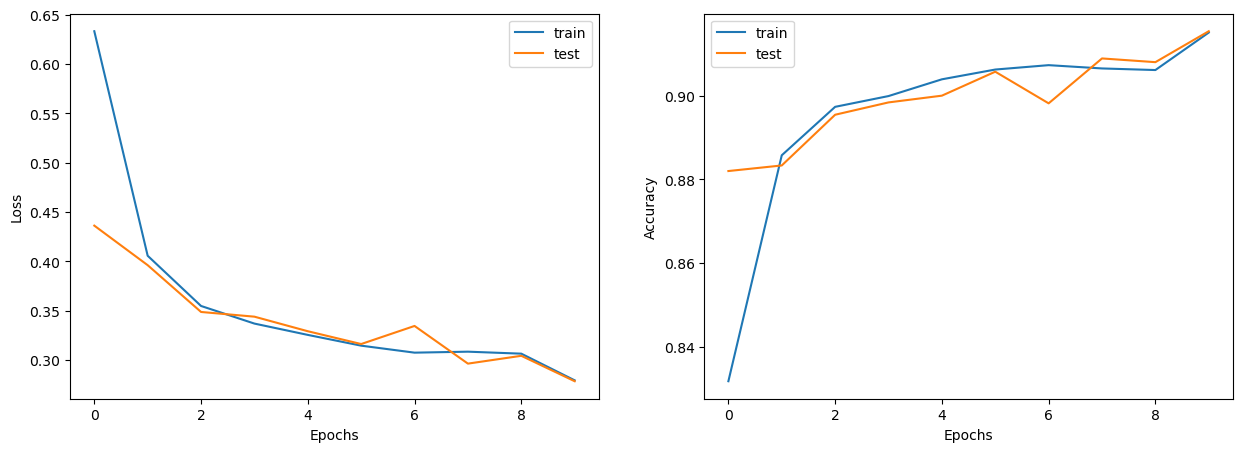

In [15]:
figure, axis = plt.subplots(ncols=2, figsize=(15,5))
axis[0].plot(history1.history['loss'])
axis[0].plot(history1.history['val_loss'])
axis[0].set_xlabel('Epochs')
axis[0].set_ylabel('Loss')
axis[0].legend(['train','test'])
axis[1].plot(history1.history['accuracy'])
axis[1].plot(history1.history['val_accuracy'])
axis[1].set_xlabel('Epochs')
axis[1].set_ylabel('Accuracy')
axis[1].legend(['train','test'])
plt.show()

In [16]:
train_evaluation =ann.evaluate(X_train, y_train)
test_evaluation= ann.evaluate(X_test, y_test)
print("-"*80)
print(f"Train Loss = {train_evaluation[0]}, Train Accuracy = {train_evaluation[1]}")
print("-"*80)
print(f"Test Loss = {test_evaluation[0]}, Test Accuracy = {test_evaluation[1]}")
print("-"*80)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9194 - loss: 0.2679
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9213 - loss: 0.2741
--------------------------------------------------------------------------------
Train Loss = 0.26787620782852173, Train Accuracy = 0.9193833470344543
--------------------------------------------------------------------------------
Test Loss = 0.2740952670574188, Test Accuracy = 0.9212999939918518
--------------------------------------------------------------------------------


In [17]:
from sklearn.metrics import classification_report
import numpy as np
import seaborn as sns

In [18]:
pip install -q seaborn

Note: you may need to restart the kernel to use updated packages.


In [19]:
pip install -q scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [20]:
pred = ann.predict(X_test)
predictions = np.argmax(pred, axis=1)
predictions

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 906us/step


array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [21]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.93      0.98      0.96       980
           1       0.97      0.98      0.97      1135
           2       0.92      0.91      0.91      1032
           3       0.91      0.90      0.90      1010
           4       0.91      0.93      0.92       982
           5       0.91      0.89      0.90       892
           6       0.93      0.95      0.94       958
           7       0.92      0.93      0.92      1028
           8       0.89      0.88      0.89       974
           9       0.92      0.87      0.89      1009

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



Text(50.722222222222214, 0.5, 'Actual')

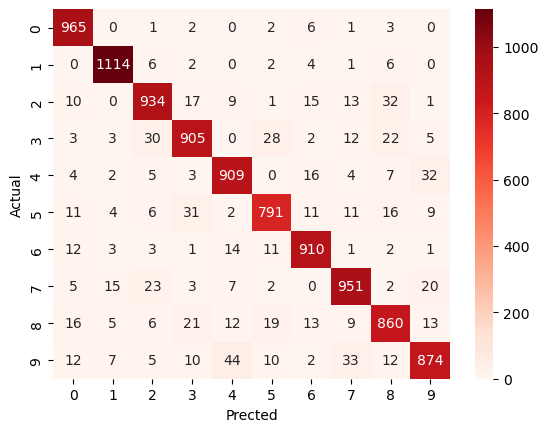

In [22]:
cm = tf.math.confusion_matrix(labels=y_test, predictions=predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Prected')
plt.ylabel('Actual')

### Scale Data

In [23]:
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0
history2 = ann.fit(X_train_scaled, y_train, epochs=10, validation_split=0.3)

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9380 - loss: 0.2182 - val_accuracy: 0.9421 - val_loss: 0.2015
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9496 - loss: 0.1729 - val_accuracy: 0.9503 - val_loss: 0.1734
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9568 - loss: 0.1455 - val_accuracy: 0.9548 - val_loss: 0.1551
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9638 - loss: 0.1237 - val_accuracy: 0.9588 - val_loss: 0.1413
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9706 - loss: 0.1046 - val_accuracy: 0.9613 - val_loss: 0.1303
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9755 - loss: 0.0889 - val_accuracy: 0.9640 - val_loss: 0.1206
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9791 - loss: 0.0750 - val_accuracy: 0.9657 - val_loss: 0.1124
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9828 - loss: 0.0638 - 

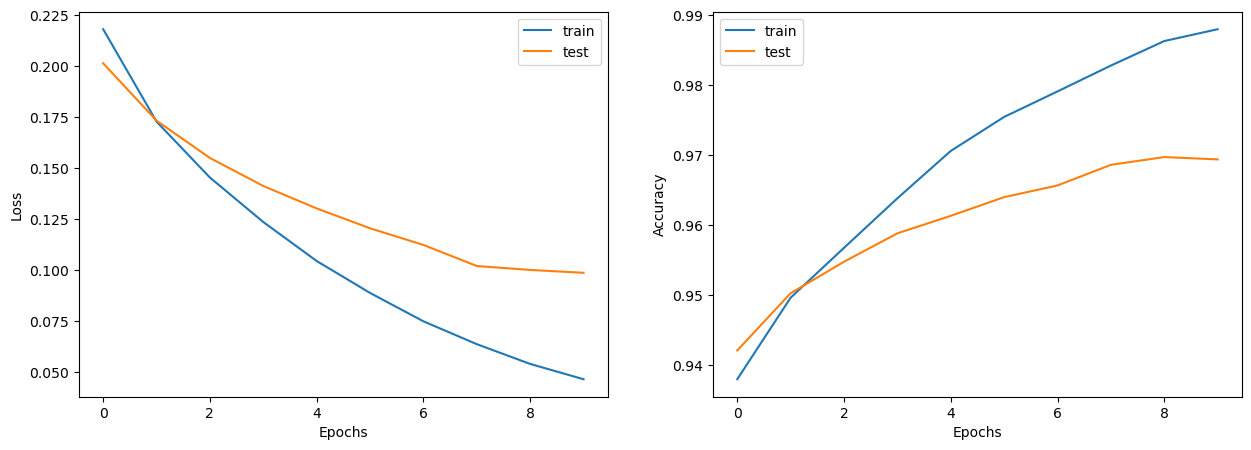

In [24]:
figure, axis = plt.subplots(ncols=2, figsize=(15,5))
axis[0].plot(history2.history['loss'])
axis[0].plot(history2.history['val_loss'])
axis[0].set_xlabel('Epochs')
axis[0].set_ylabel('Loss')
axis[0].legend(['train','test'])
axis[1].plot(history2.history['accuracy'])
axis[1].plot(history2.history['val_accuracy'])
axis[1].set_xlabel('Epochs')
axis[1].set_ylabel('Accuracy')
axis[1].legend(['train','test'])
plt.show()

In [25]:
train_evaluation =ann.evaluate(X_train, y_train)
test_evaluation= ann.evaluate(X_test, y_test)
print("-"*80)
print(f"Train Loss = {train_evaluation[0]}, Train Accuracy = {train_evaluation[1]}")
print("-"*80)
print(f"Test Loss = {test_evaluation[0]}, Test Accuracy = {test_evaluation[1]}")
print("-"*80)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9786 - loss: 0.0720
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9657 - loss: 0.1146
--------------------------------------------------------------------------------
Train Loss = 0.07203196734189987, Train Accuracy = 0.9786333441734314
--------------------------------------------------------------------------------
Test Loss = 0.11457805335521698, Test Accuracy = 0.9656999707221985
--------------------------------------------------------------------------------


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9786 - loss: 0.0720
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9657 - loss: 0.1146
--------------------------------------------------------------------------------
Train Loss = 0.07203196734189987, Train Accuracy = 0.9786333441734314
--------------------------------------------------------------------------------
Test Loss = 0.11457805335521698, Test Accuracy = 0.9656999707221985
--------------------------------------------------------------------------------
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       980
           1       0.98      0.99      0.99      1135
           2       0.97      0.97      0.97      1032
           3       0.94      0.98      0.96      1010
           4       0.96      0.96      0.96       982
           5       0.98      0.94      0.96       892
           6       0.97      0.97      0.97  

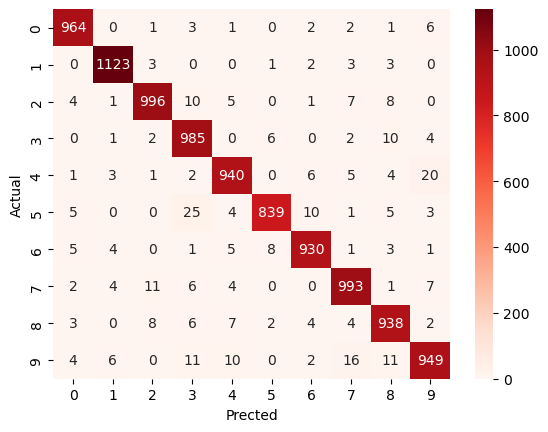

In [26]:
train_evaluation =ann.evaluate(X_train, y_train)
test_evaluation= ann.evaluate(X_test, y_test)
print("-"*80)
print(f"Train Loss = {train_evaluation[0]}, Train Accuracy = {train_evaluation[1]}")
print("-"*80)
print(f"Test Loss = {test_evaluation[0]}, Test Accuracy = {test_evaluation[1]}")
print("-"*80)

pred = ann.predict(X_test)
predictions = np.argmax(pred, axis=1)
print(classification_report(y_test, predictions))

cm = tf.math.confusion_matrix(labels=y_test, predictions=predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Prected')
plt.ylabel('Actual')
plt.show()

### CNN

In [27]:
cnn = keras.Sequential([
    keras.layers.Input((28,28,1)),
    keras.layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu'),
    keras.layers.MaxPool2D((2,2)),
    keras.layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),
    keras.layers.MaxPool2D((2,2)),
    keras.layers.Flatten(),
    #keras.layers.Dropout(0.2),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])
cnn.compile(
    optimizer='adam', 
    loss= 'sparse_categorical_crossentropy', 
    metrics=['accuracy'] 
    )

In [28]:
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │       160,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,926 (702.84 KB)

 Trainable params: 179,926 (702.84 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0
history3 = cnn.fit(X_train_scaled, y_train, epochs=10, validation_split=0.3)

Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9506 - loss: 0.1614 - val_accuracy: 0.9688 - val_loss: 0.1001
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9837 - loss: 0.0529 - val_accuracy: 0.9862 - val_loss: 0.0474
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9884 - loss: 0.0360 - val_accuracy: 0.9861 - val_loss: 0.0467
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9915 - loss: 0.0259 - val_accuracy: 0.9866 - val_loss: 0.0497
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9936 - loss: 0.0198 - val_accuracy: 0.9837 - val_loss: 0.0577
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9951 - loss: 0.0155 - val_accuracy: 0.9863 - val_loss: 0.0471
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9963 - loss: 0.0111 - val_accuracy: 0.9891 - val_loss: 0.0418
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.9970 - loss: 0.0092 -

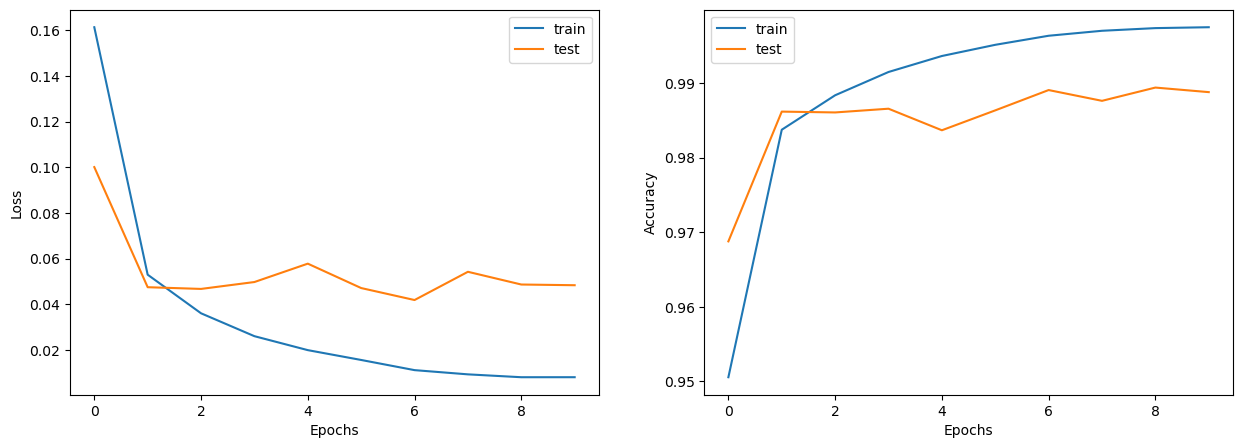

In [30]:
figure, axis = plt.subplots(ncols=2, figsize=(15,5))
axis[0].plot(history3.history['loss'])
axis[0].plot(history3.history['val_loss'])
axis[0].set_xlabel('Epochs')
axis[0].set_ylabel('Loss')
axis[0].legend(['train','test'])
axis[1].plot(history3.history['accuracy'])
axis[1].plot(history3.history['val_accuracy'])
axis[1].set_xlabel('Epochs')
axis[1].set_ylabel('Accuracy')
axis[1].legend(['train','test'])
plt.show()

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9917 - loss: 6.5805
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9850 - loss: 13.2040
--------------------------------------------------------------------------------
Train Loss = 6.580482482910156, Train Accuracy = 0.9916666746139526
--------------------------------------------------------------------------------
Test Loss = 13.203974723815918, Test Accuracy = 0.9850000143051147
--------------------------------------------------------------------------------
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       980
           1       1.00      0.99      0.99      1135
           2       0.95      1.00      0.97      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.98      0.98       892
           6       0.98      0.99      0.98      

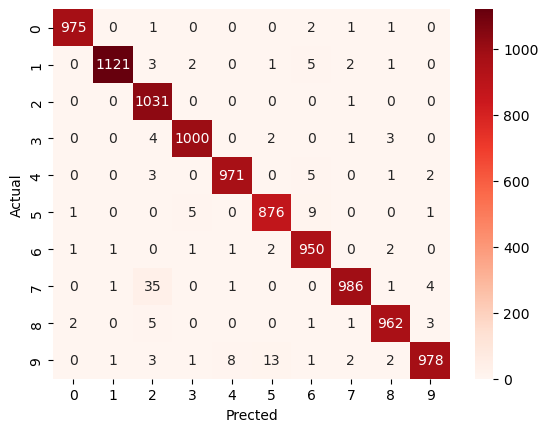

In [31]:
train_evaluation =cnn.evaluate(X_train, y_train)
test_evaluation= cnn.evaluate(X_test, y_test)
print("-"*80)
print(f"Train Loss = {train_evaluation[0]}, Train Accuracy = {train_evaluation[1]}")
print("-"*80)
print(f"Test Loss = {test_evaluation[0]}, Test Accuracy = {test_evaluation[1]}")
print("-"*80)

pred = cnn.predict(X_test)
predictions = np.argmax(pred, axis=1)
print(classification_report(y_test, predictions))

cm = tf.math.confusion_matrix(labels=y_test, predictions=predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Prected')
plt.ylabel('Actual')
plt.show()

### **Prediction**

In [32]:
!pip install opencv-python


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\surfa\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [35]:
!pip install opencv-python
%pip install opencv-python


[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: C:\Users\surfa\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 6.4 MB/s eta 0:00:07
   -------- ------------------------------- 9.7/44.0 MB 39.8 MB/s eta 0:00:01
   ------------------ --------------------- 20.2/44.0 MB 44.7 MB/s eta 0:00:01
   ----------------------- ---------------- 25.4/44.0 MB 38.3 MB/s eta 0:00:01
   -------------------------- ------------- 29.4/44.0 MB 33.7 MB/s eta 0:00:01
   ------------------------------ --------- 33.6/44.0 MB 30.8 MB/s eta 0:00:01
   ---------------------------------- ----- 38.0/44.0 MB 29.0 MB/s eta 0:00:01
   -------------------------------------- - 41.9/44.0 MB 27.9 MB/s eta 0:00:01
   ---------------------------------------- 44.0/44.0 MB 26.1 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


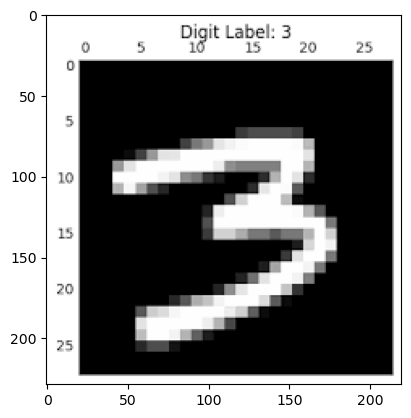

In [37]:
import cv2
img = cv2.imread('3.png')
plt.imshow(img)
plt.show()

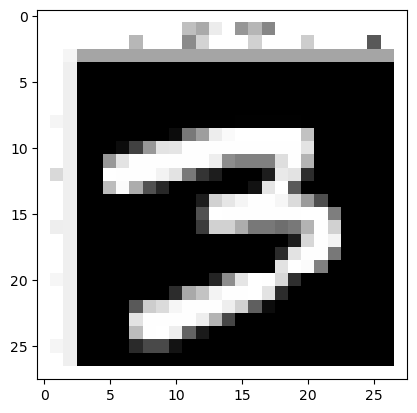

In [38]:
img_resized = tf.image.resize(img,size=(28,28))
gray_image = tf.image.rgb_to_grayscale(img_resized)
plt.imshow(gray_image)

In [39]:
gray_image.shape

TensorShape([28, 28, 1])

In [40]:
predicted = cnn.predict(np.expand_dims(gray_image/255,0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


In [41]:
print(np.argmax(predicted))

3


### **Saving the trained model**

In [42]:
import os

In [43]:
ann.save(os.path.join('models','ann_image_classifier_v1.h5'))
cnn.save(os.path.join('models','cnn_image_classifier_V1.h5'))

### **Loading the trained model**

In [44]:
from tensorflow.keras.models import load_model
new_model = load_model('models/cnn_image_classifier_V1.h5')

In [45]:
pred = new_model.predict(np.expand_dims(gray_image/255,0))
print(np.argmax(pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
3
